# Gezamenlijke exponent- en mantissatraining / A32 — honderd-epochtraining

E4M3 is de hoogste MX-bron uit de actuele FP32-gewichten. E2M3 ontstaat door de **hoogste twee exponentbits** te behouden; E2M1 ontstaat vervolgens door de **twee laagste mantissabits** te verwijderen. Alle drie modi gebruiken binnen een minibatch dezelfde E4M3-broncodes en **ongewijzigde E8M0-bronschaalbytes**. Er is geen schaalcompensatie of geleerde schaal. De bron wordt bij volgende minibatches opnieuw uit de actuele gewichten bepaald.

De FP32-updatemaster is gedeeld; iedere modus heeft een eigen BN-bank die tijdens training normaal meeleert. Activaties blijven A32. Het notebook leest uitsluitend opgeslagen JSON/CSV; het laadt geen dataset, model, checkpoint of optimizer en start geen training.

**Hoofdvergelijking:** het vaste eindpunt **epoch 100** en het beste checkpoint gekozen door E4M3; telkens de drie modi van één en dezelfde epoch. Bij een gecontroleerde vroege stop toont de notebook de laatste beschikbare epoch en meldt hij expliciet dat epoch 100 nog niet is gemeten. Ontbrekende resultaten worden niet voorspeld.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_truncation_aware_reference100\\20261023_184058_211397_joint_run')
SAVE_FIGURES = True  # Nieuwe analysemap; ruwe resultaten blijven behouden.


In [2]:
import sys
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:
    class Markdown(str):
        pass
    def display(value):
        print(value)

# Gebruik de helper uit déze run, ook als een eerdere notebook dezelfde modulenaam gebruikte.
helper_path = RUN_DIR.expanduser().resolve() / 'notebook_support.py'
helper_name = '_mx_triple_truncation_aware_analysis_helper'
spec = importlib.util.spec_from_file_location(helper_name, helper_path)
if spec is None or spec.loader is None:
    raise FileNotFoundError(f'Analysehelper ontbreekt: {helper_path}')
ns = importlib.util.module_from_spec(spec)
sys.modules[helper_name] = ns
spec.loader.exec_module(ns)
run = ns.load_run(RUN_DIR)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(Markdown('### Meldingen en ontbrekende gegevens'))
display(ns.diagnostics_table(run))


### Opgeslagen SVHN-run — herkomst volgens het runrapport

Runstatus: **PASS** · Analysefouten: **0**. Laatste ingelezen testepoch: **100**.

**Alle honderd epochs voor alle drie modi aanwezig; volledige referentie volgens het runrapport.** Epoch100 staat naast het door E4M3 gekozen beste checkpoint.

Deze analyse leest uitsluitend opgeslagen JSON/CSV. Zij start geen training en laadt geen model of checkpoint.

,Onderdeel,Opgeslagen configuratie
0,Gewichtsmodi,"MXFP8_E4M3, MXFP6_E2M3, MXFP4_E2M1"
1,Gewichtsroute,E4M3-bron uit actueel G(W) → E2M3 via exponent...
2,Schaal bij lagere modi,Exact dezelfde E4M3-bronschaalbytes; geen comp...
3,Schaal tijdens training,Bron wordt opnieuw bepaald uit actuele gewicht...
4,BatchNorm,Eigen doelbank per modus leert mee tijdens tra...
5,Schaalbeleid,encode current E4M3 source scale floor(log2(am...
6,Activaties / updatemaster,A32 / float32
7,Distillatie,E4M3 hard CE + E2M3 soft CE from detached E4M3...
8,Gezamenlijke update,Drie passes; som van gradients zonder deling d...
9,BN-banken per gewichtsmodus,"{'8': '8', '6': '32', '4': '4'}"


### Meldingen en ontbrekende gegevens

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## Epoch 100 en beste checkpoint gekozen door E4M3

Het beste checkpoint is het **eerste strikte maximum van de E4M3-testaccuracy**. Een gelijke score vervangt het eerdere checkpoint niet. E2M3 en E2M1 worden op precies diezelfde epoch gerapporteerd, ook wanneer hun eigen hoogste score elders ligt. Er worden geen afzonderlijke beste epochs tot één resultaat gecombineerd.

De officiële testset wordt volgens het bestaande protocol voor checkpointselectie gebruikt. De beste score is daardoor geen onafhankelijke testschatting na selectie. Het vaste eindpunt epoch 100 blijft apart zichtbaar. Bij een vroeg gestopte run wordt de laatste beschikbare epoch getoond. **Epoch 100 ontbreekt totdat honderd volledige epochs aantoonbaar zijn opgeslagen.** Er wordt geen ontbrekende accuracy geëxtrapoleerd.


,Rol,Controlepunt,Epoch,Gewichtsformaat,Testaccuracy [%],Correct / n,Harde test-CE,Selectiebron,Checkpoint
0,last_epoch,Laatste beschikbare epoch,100,MXFP8_E4M3,86.397511,22.491 / 26.032,0.436818,checkpoint_selection.json,last_checkpoint.pt
1,last_epoch,Laatste beschikbare epoch,100,MXFP6_E2M3,87.062077,22.664 / 26.032,0.420150,checkpoint_selection.json,last_checkpoint.pt
2,last_epoch,Laatste beschikbare epoch,100,MXFP4_E2M1,87.138906,22.684 / 26.032,0.421968,checkpoint_selection.json,last_checkpoint.pt
3,best_E4M3_test,Beste checkpoint gekozen door E4M3,54,MXFP8_E4M3,86.793178,22.594 / 26.032,0.430299,checkpoint_selection.json,best_checkpoint.pt
4,best_E4M3_test,Beste checkpoint gekozen door E4M3,54,MXFP6_E2M3,87.530731,22.786 / 26.032,0.415061,checkpoint_selection.json,best_checkpoint.pt
5,best_E4M3_test,Beste checkpoint gekozen door E4M3,54,MXFP4_E2M1,87.565304,22.795 / 26.032,0.420402,checkpoint_selection.json,best_checkpoint.pt
6,epoch100,Vast eindpunt epoch100,100,MXFP8_E4M3,86.397511,22.491 / 26.032,0.436818,alle drie modi; volledige referentie bevestigd,niet gerapporteerd
7,epoch100,Vast eindpunt epoch100,100,MXFP6_E2M3,87.062077,22.664 / 26.032,0.420150,alle drie modi; volledige referentie bevestigd,niet gerapporteerd
8,epoch100,Vast eindpunt epoch100,100,MXFP4_E2M1,87.138906,22.684 / 26.032,0.421968,alle drie modi; volledige referentie bevestigd,niet gerapporteerd


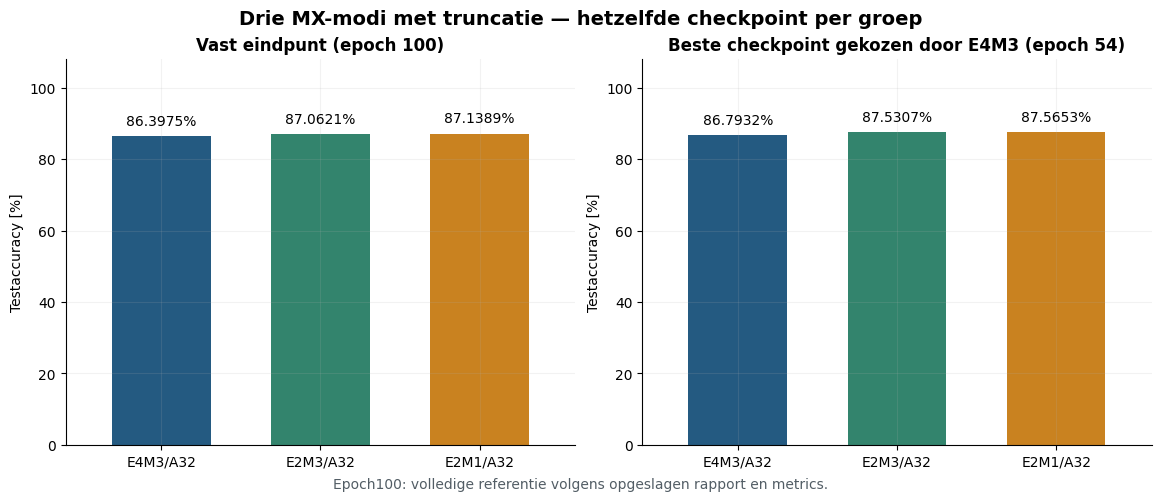

In [3]:
display(ns.checkpoint_table(run).round({'Testaccuracy [%]': 6, 'Harde test-CE': 8}))
figures['checkpoint_accuracy'] = ns.plot_checkpoint_accuracy(run)
display(figures['checkpoint_accuracy'])
plt.close(figures['checkpoint_accuracy'])


## Train- en testaccuracy per modus

Alle drie routes worden vanaf een nieuwe initialisatie gezamenlijk getraind. E4M3 gebruikt gewone directe MX-kwantisatie; de twee lagere routes gebruiken uitsluitend de afgesproken bittruncaties van die bron. De testfase gebruikt **dezelfde truncatieroutes** als de training.

Trainaccuracy is tijdens de updates verzameld. Testaccuracy wordt na iedere epoch met bevroren evaluatiestaat gemeten, op dezelfde volledige testset voor alle modi. BN-statistieken worden tijdens training per modus geleerd; zij worden tijdens de testfase niet aangepast.


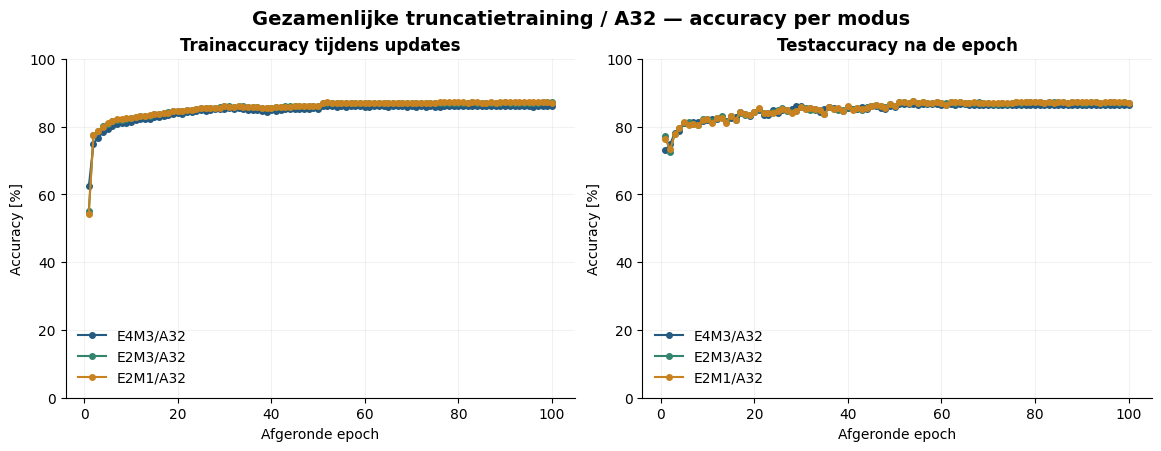

In [4]:
figures['accuracy_curves'] = ns.plot_learning(run)
display(figures['accuracy_curves'])
plt.close(figures['accuracy_curves'])


## Blijft het netwerk verschillende cijfers voorspellen?

De eerdere post-hocproef leverde voor de exponentroutes één vaste klasse op. Daarom wordt hier per testepoch en per modus bijgehouden hoe de voorspellingen over de tien cijfers verdeeld zijn. Een constante voorspelling is direct zichtbaar als **één gebruikte klasse en 100% concentratie**. De tabel toont ook hoe vaak het dominante cijfer werkelijk in de testset voorkomt.

Dit zijn geaggregeerde tellingen; deze notebook doet geen nieuwe inferentie en leidt er geen per-beeldvergelijking uit af.


,Rol,Epoch,Gewichtsformaat,Voorspelde klassen,Meest voorspelde cijfer,Aandeel dominant cijfer [%],Aandeel dat cijfer in labels [%],Testaccuracy [%],Constante voorspelling,Testbeelden,Tellingen voorspeld cijfer 0..9,Tellingen echt cijfer 0..9
0,last_epoch,100,MXFP8_E4M3,10,1,19.314690,19.587431,86.397511,False,26032,"[1692, 5028, 4233, 2962, 2586, 2262, 1877, 205...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
1,last_epoch,100,MXFP6_E2M3,10,1,19.341580,19.587431,87.062077,False,26032,"[1698, 5035, 4311, 2893, 2607, 2262, 1899, 203...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
2,last_epoch,100,MXFP4_E2M1,10,1,19.214813,19.587431,87.138906,False,26032,"[1697, 5002, 4320, 2910, 2609, 2285, 1902, 205...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
3,best_E4M3_test,54,MXFP8_E4M3,10,1,19.591272,19.587431,86.793178,False,26032,"[1684, 5100, 4195, 2994, 2566, 2292, 1903, 203...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
4,best_E4M3_test,54,MXFP6_E2M3,10,1,19.629687,19.587431,87.530731,False,26032,"[1776, 5110, 4220, 2914, 2540, 2301, 1958, 205...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
5,best_E4M3_test,54,MXFP4_E2M1,10,1,19.806392,19.587431,87.565304,False,26032,"[1747, 5156, 4245, 2943, 2548, 2366, 1937, 200...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."


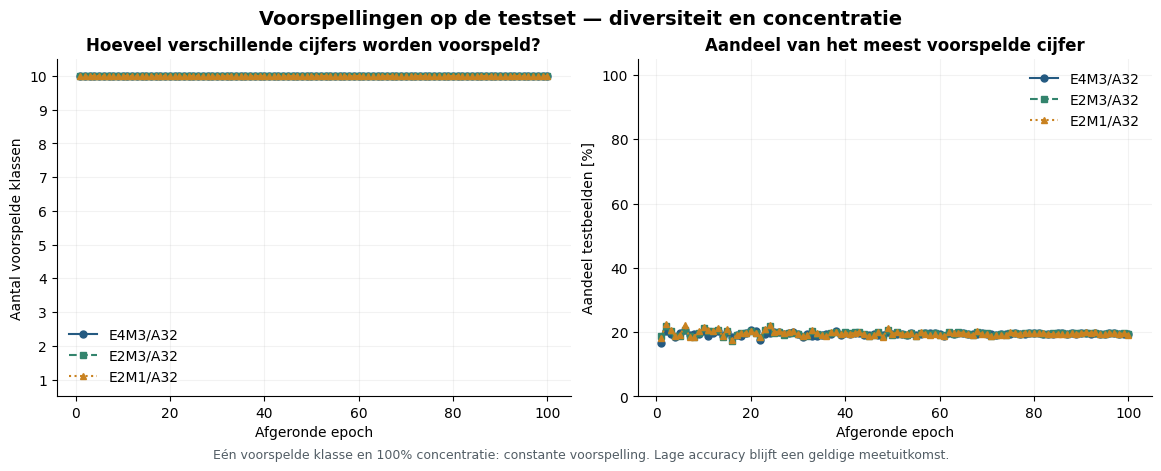

In [5]:
display(ns.prediction_table(run, selected_only=True))
figures['prediction_diversity'] = ns.plot_prediction_diversity(run)
display(figures['prediction_diversity'])
plt.close(figures['prediction_diversity'])


## Losses: trainingsdoelen onderscheiden van harde test-CE

De trainpass van E4M3 gebruikt harde CE van labels. Daarna leert E2M3 met soft-target CE van de **detached E4M3-softmax**; E2M1 leert met soft-target CE van de **detached E2M3-softmax**. Dit is recursieve distillatie met T=1. De drie gradients worden gesommeerd zonder deling door drie, waarna één Adam-update volgt; er is geen extra FP32-teacherforward.

De drie trainobjectieven staan in afzonderlijke panelen omdat hun targets verschillen. Soft CE is geen harde label-CE en wordt hier ook niet als KL-divergentie aangeduid. **Testloss is voor alle drie modi harde CE van dezelfde labels** en staat daarom samen in één vergelijkbaar paneel.


,epoch,phase,weight_format,objective_type,objective_loss
0,1,train,MXFP4_E2M1,recursive_soft_cross_entropy,1.936632
1,1,train,MXFP6_E2M3,recursive_soft_cross_entropy,1.569530
2,1,train,MXFP8_E4M3,hard_cross_entropy,1.322210
3,1,test,MXFP4_E2M1,hard_cross_entropy,0.932882
4,1,test,MXFP6_E2M3,hard_cross_entropy,0.879501
...,...,...,...,...,...
595,100,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.501743
596,100,train,MXFP8_E4M3,hard_cross_entropy,0.448308
597,100,test,MXFP4_E2M1,hard_cross_entropy,0.421968
598,100,test,MXFP6_E2M3,hard_cross_entropy,0.420150


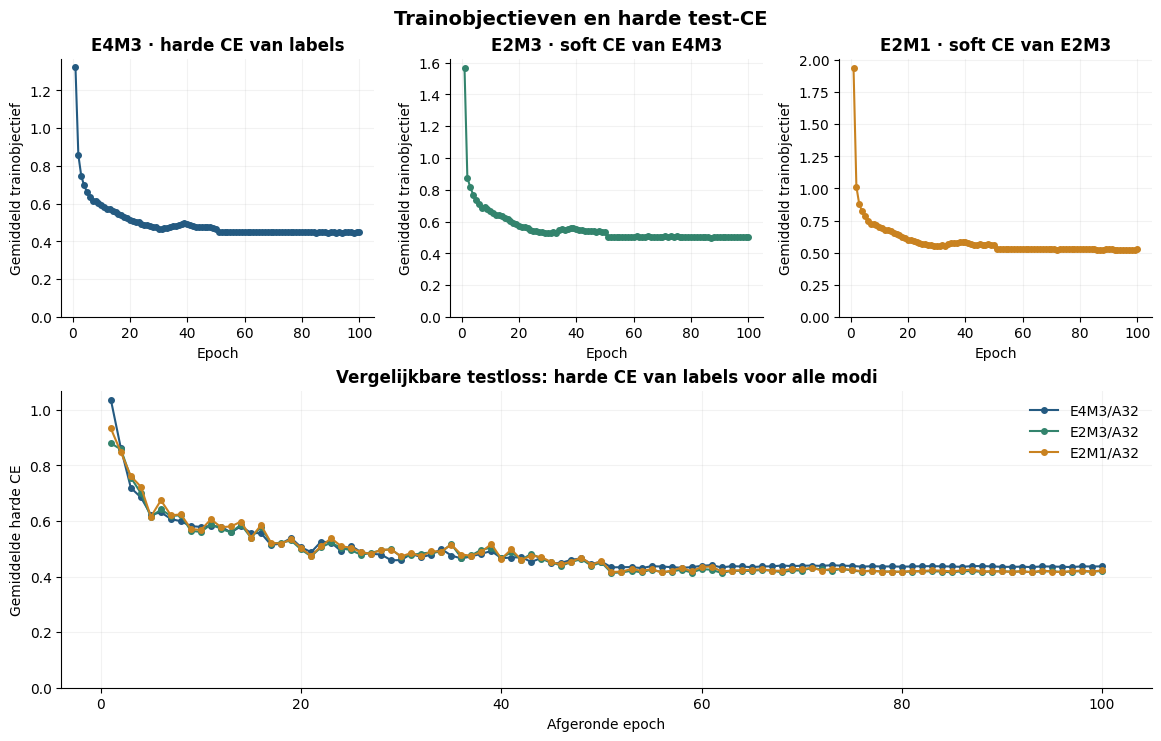

In [6]:
if not run.metrics.empty:
    objective_columns = [key for key in ('epoch', 'phase', 'weight_format', 'objective_type', 'objective_loss') if key in run.metrics]
    display(run.metrics[objective_columns].round({'objective_loss': 8}))
figures['objective_losses'] = ns.plot_objectives(run)
display(figures['objective_losses'])
plt.close(figures['objective_losses'])


## Gemeten trainingsduur en eventuele projectie bij een vroege stop

**Gemeten som over 100 afgeronde epochs: 5400.42 s (90.01 minuten).** Alle honderd epochs zijn aanwezig. De gemeten duur omvat train, test, epochcontroles en checkpointschrijven; een eerdere projectie wordt hiervoor niet gebruikt. Download, installatie, data-inladen, eindrapportage en sessiepauzes zijn niet inbegrepen.

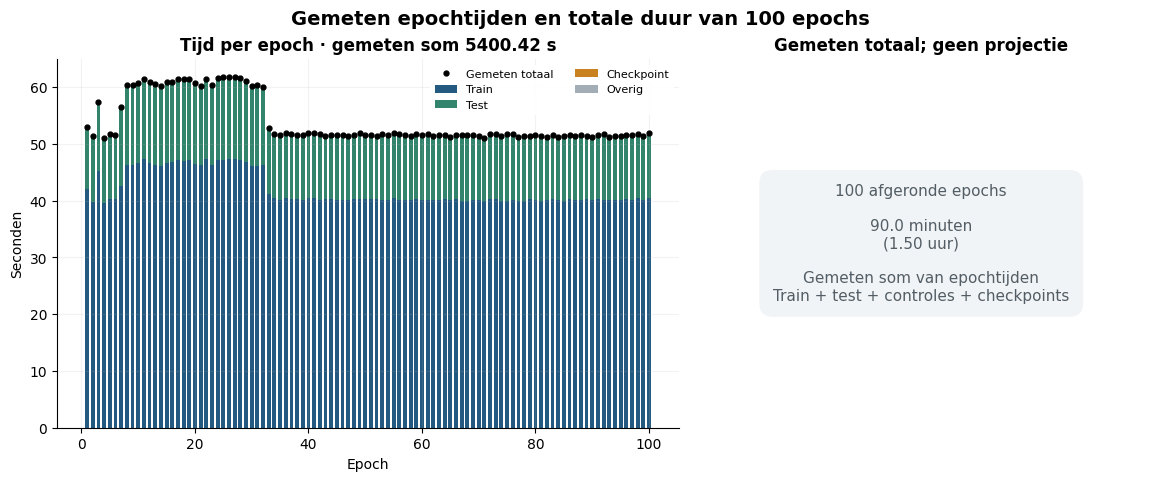

In [7]:
display(Markdown('## Gemeten trainingsduur en eventuele projectie bij een vroege stop'))
display(Markdown(ns.timing_markdown(run)))
figures['timing'] = ns.plot_timing(run)
display(figures['timing'])
plt.close(figures['timing'])


## GPU-geheugen

De opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.

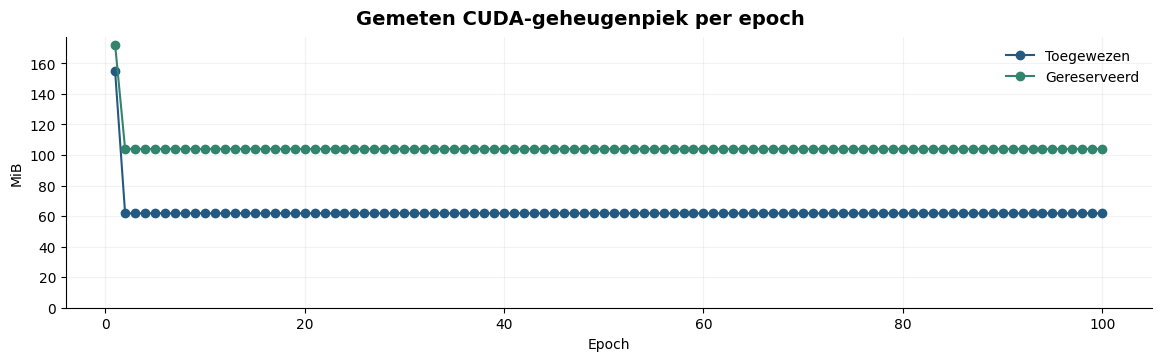

In [8]:
display(Markdown('## GPU-geheugen\n\nDe opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.'))
figures['gpu_memory'] = ns.plot_memory(run)
display(figures['gpu_memory'])
plt.close(figures['gpu_memory'])


In [9]:
display(Markdown('## Opgeslagen technische controles\n\nDeze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.'))
display(ns.audit_table(run))
display(Markdown('### Gewichtsupdates\n\nDe mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.'))
display(ns.weight_update_table(run))
display(Markdown('### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint'))
display(ns.export_table(run))


## Opgeslagen technische controles

Deze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.

,Opgeslagen controle,Resultaat volgens rapport
0,Gradientcontrole vóór iedere gezamenlijke update,True
1,FP32-masters en Adam-momenten geverifieerd,True
2,BN-tellers van alle opgeslagen epochs correct,True
3,Geen optimizerupdates tijdens evaluatie,True
4,Bronbestanden onveranderd,True
5,Ruwe datasetbestanden onveranderd,True
6,Gezamenlijke optimizerupdates,57300
7,Trainforwardpasses; verwacht driemaal updates,171900
8,Alle modi van hetzelfde geselecteerde checkpoint,True
9,Selectie op officiële testset,True


### Gewichtsupdates

De mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.

,epoch,weight_format,layer,master_changed_values,master_update_l2,master_dtype,changed_element_codes_including_padding,changed_scale_codes
0,1,MXFP4_E2M1,layers.3,1728,2.350310,torch.float32,1163,0
1,1,MXFP6_E2M3,layers.3,1728,2.350310,torch.float32,1576,0
2,1,MXFP8_E4M3,layers.3,1728,2.350310,torch.float32,1665,0
3,1,MXFP4_E2M1,layers.6,2304,2.624305,torch.float32,1571,0
4,1,MXFP6_E2M3,layers.6,2304,2.624305,torch.float32,2137,0
...,...,...,...,...,...,...,...,...
1795,100,MXFP6_E2M3,layers.16,9213,0.002120,torch.float32,309,0
1796,100,MXFP8_E4M3,layers.16,9213,0.002120,torch.float32,312,0
1797,100,MXFP4_E2M1,layers.20,102161,0.007793,torch.float32,339,0
1798,100,MXFP6_E2M3,layers.20,102161,0.007793,torch.float32,1065,0


### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint

,Rol,Epoch,Gewichtsformaat,Bestand,Bestandsbytes,Gewichten exact gereconstrueerd,Zes FP32-masters afwezig,Volledige exporttest opnieuw,Truncatie,Bron of afleiding,Bronschaalbytes behouden,Masters gelezen voor afleiding,Opgeslagen en herladen,Bronbestand-SHA256
0,best_E4M3_test,54,MXFP8_E4M3,mx_source_MXFP8_E4M3_best.pt,196773,True,True,False,False,E4M3-bron,True,False,True,66f2dea1b6877a2a9c60114420c22fb6bc02aae6707af0...
1,best_E4M3_test,54,MXFP6_E2M3,mx_derived_MXFP6_E2M3_best.pt,164517,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,True,False,True,66f2dea1b6877a2a9c60114420c22fb6bc02aae6707af0...
2,best_E4M3_test,54,MXFP4_E2M1,mx_derived_MXFP4_E2M1_best.pt,131877,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,True,False,True,66f2dea1b6877a2a9c60114420c22fb6bc02aae6707af0...
3,last_epoch,100,MXFP8_E4M3,mx_source_MXFP8_E4M3_last.pt,196773,True,True,False,False,E4M3-bron,True,False,True,5a368330de15812becb495bd11967d69a2046ff3f4a81c...
4,last_epoch,100,MXFP6_E2M3,mx_derived_MXFP6_E2M3_last.pt,164517,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,True,False,True,5a368330de15812becb495bd11967d69a2046ff3f4a81c...
5,last_epoch,100,MXFP4_E2M1,mx_derived_MXFP4_E2M1_last.pt,131877,True,True,False,True,afgeleid uit opgeslagen E4M3-bron,True,False,True,5a368330de15812becb495bd11967d69a2046ff3f4a81c...


## Interpretatie en grenzen

Deze training onderzoekt of gezamenlijk trainen met de **naïeve exponentbitbewerking en daaropvolgende mantissabitshift** de drie uitvoermodi laat leren. De lagere modi mogen geen directe E2-encoder of afzonderlijke E2-schaalkeuze gebruiken. Het behoud van de E4M3-bronschaal gebeurt per actuele bron; de schaal is niet voor de volledige training vastgezet op haar beginwaarde.

Een lage accuracy of voorspelling van één vaste klasse blijft een onderzoeksuitkomst zolang de technische controles slagen. Een dalende soft-target trainingsloss bewijst op zichzelf geen verbeterde beeldherkenning. Bekijk daarom steeds harde test-CE, testaccuracy én de voorspellingstellingen.

Deze proef gebruikt één seed. Een vergelijking met de directe referentie of de eerdere post-hocproef betreft apart getrainde gewichten en bijbehorende BN-banken; zij is geen geïsoleerde meting van één oorzaak. Deze notebook presenteert uitsluitend de opgeslagen metingen van deze training. De beste checkpointscore op de officiële testset en de score op het vaste eindpunt beantwoorden verschillende selectievragen.

De bronexport bevat de E4M3-codes, E8M0-schalen en benodigde overige modelstaat. De afgeleide exports worden uit de opgeslagen en herladen bron gemaakt; de zes MX-updatemasters zijn daarin afwezig. De exporttabel maakt zichtbaar welke reconstructiecontroles zijn uitgevoerd. De drie BN-banken en FP32-uitzonderingslagen blijven benodigde modelstaat.

A32 en FP32 beschrijven tensor- en masterdtypes. De opgeslagen CUDA-backendprecisie staat apart in de protocoltabel; cuDNN kan intern TF32 gebruiken. Dit is een MX-emulator, geen meting van native MX-snelheid of energie.

`SAVE_FIGURES = True` schrijft de zes figuren en een analysemanifest naar een **nieuwe** map. De runner kan dit voor de runkopie inschakelen. JSON, CSV, checkpoints en eerdere analyses blijven ongewijzigd.


In [10]:
if SAVE_FIGURES:
    analysis_dir = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', analysis_dir)
else:
    print('Alleen analyse in het notebook; geen figuren naar schijf geschreven.')
print('Ingelezen resultaatmap:', run.path)
display(pd.DataFrame({'Ingelezen bestand': [path.name for path in run.input_files]}))


Figuren opgeslagen in: C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_truncation_aware_reference100\20261023_184058_211397_joint_run\analysis_20261023_201232_025588
Ingelezen resultaatmap: C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_truncation_aware_reference100\20261023_184058_211397_joint_run


,Ingelezen bestand
0,run_report.json
1,history.json
2,training_summary.json
3,checkpoint_selection.json
4,timing_estimate.json
5,epoch_metrics.csv
6,selected_metrics.csv
7,epoch_times.csv
8,weight_updates.csv
